# Phase 3 – MFCC Feature Extraction
**Gujarati Accent Classifier**

This notebook turns each standardised WAV recording into **MFCC**, **delta** and **delta-delta** features, saves the complete frame-level matrices, builds a one-row-per-recording feature table, and visualises the result.

**Scope and caveats**
- Input: the Phase 1 WAV files in `dataset/processed/wav/` (read-only; no audio is modified, trimmed, denoised or normalised).
- Output: `results/mfcc/` (NPZ arrays, CSV tables, validation summary, figures).
- There is **one speaker per accent**. Any difference in these features can come from the accent, the speaker, the microphone/app, the room, the original file format (M4A vs OGG) or the words used. Figures are descriptive only; they do not prove accent discrimination.
- No PCA, feature selection or classification is done here (Phase 4 onwards).
- Surti is pending. The notebook reads `dataset/recordings_metadata.csv`, so real Surti recordings are picked up automatically after Phase 1 (and, for quality flags, Phase 2) are re-run.

## 1. Imports and paths
Project config, the Phase 2 loader and the Phase 3 module `src/mfcc_features.py` are reused. Paths are relative to the project root.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import config as cfg
import audio_analysis as aa
import mfcc_features as mf

mf.FIG_DIR.mkdir(parents=True, exist_ok=True)
(mf.FIG_DIR / "per_recording").mkdir(exist_ok=True)
ACCENTS = [a.accent for a in cfg.ACCENTS]
COLORS = {"Ahmedabad": "#0072B2", "Kutchi": "#E69F00", "Mehsani": "#009E73",
          "Kathiyawadi": "#CC79A7", "Surti": "#999999"}      # same colours as Phase 2
MARKERS = {"M4A": "o", "OGG": "s"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11})
pd.set_option("display.width", 220, "display.max_columns", 40)

def save(fig, relative_name, show=True):
    path = mf.FIG_DIR / relative_name
    fig.savefig(path, bbox_inches="tight")
    print("saved:", path.relative_to(PROJECT_ROOT).as_posix())
    if show:
        plt.show()
    plt.close(fig)

## 2. Extraction parameters
Every recording is processed with exactly the same settings (stored inside each NPZ file so they can be audited later).

| Parameter | Value | Plain meaning |
|---|---|---|
| sample rate | 16,000 Hz | audio is used as-is (no resampling) |
| `n_mfcc` | 13 | 13 coefficients per frame |
| `n_fft` | 512 | 32 ms analysis block |
| `win_length` | 400 | 25 ms actual window inside the block |
| `hop_length` | 160 | a new frame every 10 ms |
| window | Hann | smooth window shape |
| DCT type / norm | 2 / ortho | the standard MFCC transform |

Also written down explicitly for reproducibility: 128 mel filters and delta width 9 frames (librosa defaults).

**Naming:** librosa's first output row (often called c0) is labelled **MFCC 1** here, so the 13 labels are MFCC 1–13. MFCC 1 mostly reflects overall energy (loudness), so it is plotted separately from MFCC 2–13 in the heatmaps.

In [2]:
pd.DataFrame({"parameter": list(mf.PARAMS), "value": list(mf.PARAMS.values())})

,parameter,value
0,sample_rate,16000
1,n_mfcc,13
2,n_fft,512
3,hop_length,160
4,win_length,400
5,window,hann
6,dct_type,2
7,norm,ortho
8,n_mels,128
9,center,True


## 3. Load metadata and Phase 2 quality flags
Phase 1 metadata is joined to the Phase 2 quality flags by `recording_id`. Flagged recordings are **kept**.

In [3]:
meta, missing_flags = mf.load_metadata_with_flags()
print("Recordings:", len(meta), "| without Phase 2 flags:", missing_flags or "none")
counts = meta.groupby("accent").size().reindex(ACCENTS, fill_value=0).rename("recordings").to_frame()
counts["note"] = counts["recordings"].map(lambda n: "pending future collection" if n == 0 else "")
display(counts)
display(meta.loc[meta["quality_flags"] != "", ["recording_id", "accent", "original_format", "quality_flags"]])

Recordings: 28 | without Phase 2 flags: none


,recordings,note
accent,,
Ahmedabad,7,
Kutchi,7,
Mehsani,7,
Kathiyawadi,7,
Surti,0,pending future collection


,recording_id,accent,original_format,quality_flags
7,KUT_S01_R01,Kutchi,M4A,level_inconsistent
14,MEH_S01_R01,Mehsani,OGG,clipping
16,MEH_S01_R03,Mehsani,OGG,clipping
19,MEH_S01_R06,Mehsani,OGG,clipping
20,MEH_S01_R07,Mehsani,OGG,clipping
21,KAT_S01_R03,Kathiyawadi,OGG,clipping
22,KAT_S01_R01,Kathiyawadi,OGG,clipping
24,KAT_S01_R04,Kathiyawadi,OGG,clipping
25,KAT_S01_R05,Kathiyawadi,OGG,clipping
26,KAT_S01_R06,Kathiyawadi,OGG,clipping


## 4. Extract MFCC, delta and delta-delta
For each recording: load the WAV unchanged, compute the 13 x T MFCC matrix, then its first (delta) and second (delta-delta) time derivatives. The **full frame-level matrices** are saved to `results/mfcc/frame_features/<recording_id>.npz`. The recording-level table holds the mean and standard deviation (over frames) of each coefficient: 13 coefficients x 3 feature groups x 2 statistics = **78 acoustic columns**. Frames from silent/pause sections are **not** removed.

In [4]:
feature_df, frames, errors = mf.extract_all(meta)
csv_path, cols_path = mf.save_feature_table(feature_df)
print("Recording-level table:", csv_path.relative_to(PROJECT_ROOT).as_posix(), feature_df.shape)
print("Feature-column list  :", cols_path.relative_to(PROJECT_ROOT).as_posix())
print("Errors:", errors or "none")

shape_table = pd.DataFrame([{"recording_id": r, "accent": feature_df.set_index("recording_id").loc[r, "accent"],
                             "mfcc_shape": frames[r]["mfcc"].shape, "delta_shape": frames[r]["delta"].shape,
                             "delta2_shape": frames[r]["delta2"].shape} for r in frames])
display(shape_table)

C:\Users\91966\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Recording-level table: results/mfcc/mfcc_recording_features.csv (28, 89)
Feature-column list  : results/mfcc/mfcc_feature_columns.json
Errors: none


,recording_id,accent,mfcc_shape,delta_shape,delta2_shape
0,AHM_S01_R01,Ahmedabad,"(13, 1419)","(13, 1419)","(13, 1419)"
1,AHM_S01_R02,Ahmedabad,"(13, 1197)","(13, 1197)","(13, 1197)"
2,AHM_S01_R03,Ahmedabad,"(13, 1199)","(13, 1199)","(13, 1199)"
3,AHM_S01_R04,Ahmedabad,"(13, 1217)","(13, 1217)","(13, 1217)"
4,AHM_S01_R05,Ahmedabad,"(13, 1726)","(13, 1726)","(13, 1726)"
5,AHM_S01_R06,Ahmedabad,"(13, 1212)","(13, 1212)","(13, 1212)"
6,AHM_S01_R07,Ahmedabad,"(13, 1645)","(13, 1645)","(13, 1645)"
7,KUT_S01_R01,Kutchi,"(13, 1515)","(13, 1515)","(13, 1515)"
8,KUT_S01_R02,Kutchi,"(13, 1697)","(13, 1697)","(13, 1697)"
9,KUT_S01_R03,Kutchi,"(13, 1541)","(13, 1541)","(13, 1541)"


Metadata columns (IDs, accent, region, format, quality flags) and acoustic columns are kept in separate, clearly named groups. `mfcc_feature_columns.json` lists exactly which columns are features. **Accent, speaker ID and recording ID must never be used as model inputs.**

In [5]:
meta_cols = mf.META_COLUMNS + mf.FLAG_COLUMNS
feat_cols = mf.feature_column_names()
print("Metadata columns :", len(meta_cols), meta_cols)
print("Acoustic columns :", len(feat_cols), "e.g.", feat_cols[:3], "...", feat_cols[-2:])
display(feature_df[meta_cols].head(3))
display(feature_df[feat_cols[:6]].round(3).head(3))

Metadata columns : 11 ['recording_id', 'speaker_id', 'accent', 'region', 'original_format', 'quality_flags', 'flag_clipping', 'flag_low_amplitude', 'flag_near_silent', 'flag_unusual_duration', 'flag_level_inconsistent']
Acoustic columns : 78 e.g. ['mfcc_01_mean', 'mfcc_01_std', 'mfcc_02_mean'] ... ['delta2_13_mean', 'delta2_13_std']


,recording_id,speaker_id,accent,region,original_format,quality_flags,flag_clipping,flag_low_amplitude,flag_near_silent,flag_unusual_duration,flag_level_inconsistent
0,AHM_S01_R01,AHM_S01,Ahmedabad,Central Gujarat,M4A,,False,False,False,False,False
1,AHM_S01_R02,AHM_S01,Ahmedabad,Central Gujarat,M4A,,False,False,False,False,False
2,AHM_S01_R03,AHM_S01,Ahmedabad,Central Gujarat,M4A,,False,False,False,False,False


,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,mfcc_03_std
0,-433.597,84.436,132.104,30.730,-25.871,26.725
1,-422.492,76.349,137.983,38.898,-16.316,27.663
2,-425.911,71.669,138.045,36.510,-23.219,25.794


## 5. Validation
Every check below must pass; failures are listed, never ignored.

In [6]:
checks, all_passed = mf.validate(meta, feature_df, frames, errors, missing_flags)
for name, ok, detail in checks:
    print(("PASS" if ok else "FAIL"), "-", name, ("-> " + detail) if detail else "")
print()
print("ALL CHECKS PASSED" if all_passed else "SOME CHECKS FAILED")
assert all_passed

PASS - No extraction errors 
PASS - All metadata recordings processed -> metadata=28, processed=28
PASS - Feature table has one row per recording, IDs match metadata 
PASS - Every recording has 13 coefficients; MFCC/delta/delta-delta shapes agree with frame count 
PASS - No NaN or infinite values in any frame-level matrix 
PASS - No NaN or infinite values in recording-level features 
PASS - Feature table has 78 acoustic columns (13 x 2 stats x 3 groups) 
PASS - A frame-level NPZ exists for each recording and stores its recording ID 
PASS - Extraction parameters identical across all recordings (stored in each NPZ) 
PASS - Phase 2 quality flags available for every recording 
PASS - Flagged recordings were kept (none removed) -> 11 flagged recordings retained

ALL CHECKS PASSED


## 6. Accent-wise summary statistics
Per accent, feature group and coefficient: the mean and spread of the **recording-level means** (n = 7 recordings per accent, so the spread is only a rough guide), plus statistics pooled over all frames of that accent. Saved to `mfcc_accent_summary.csv`.

In [7]:
summary = mf.accent_summary(feature_df, frames)
summary.to_csv(mf.MFCC_DIR / "mfcc_accent_summary.csv", index=False)
display(summary[summary.feature_group == "mfcc"].pivot(index="coefficient", columns="accent",
        values="mean_of_recording_means").reindex(columns=[a for a in ACCENTS if a in set(summary.accent)]).round(2))

accent,Ahmedabad,Kutchi,Mehsani,Kathiyawadi
coefficient,,,,
1,-429.33,-464.01,-460.86,-494.07
2,132.50,126.86,126.10,103.31
3,-19.77,7.12,13.74,6.89
4,2.35,23.70,-5.32,21.54
5,-8.23,-1.70,-9.04,-12.48
6,-3.62,1.04,-11.09,3.95
7,-22.11,-14.26,-5.80,-9.34
8,-3.82,-2.50,-19.17,-2.52
9,-19.75,-6.39,-11.71,-3.91


## 7. Plot helpers and shared colour scales
For fair comparison, **all MFCC 2–13 heatmaps share one symmetric colour scale**, and all delta (or delta-delta) heatmaps share another. MFCC 1 (energy-like) has a much larger range, so it is shown as its own line/panel with its own axis. Colour = coefficient value (no unit). Red/blue only mean positive/negative, not "good/bad".

In [8]:
all_mfcc = np.concatenate([f["mfcc"] for f in frames.values()], axis=1)
all_delta = np.concatenate([f["delta"] for f in frames.values()], axis=1)
all_delta2 = np.concatenate([f["delta2"] for f in frames.values()], axis=1)
VMAX_MFCC = float(np.percentile(np.abs(all_mfcc[1:]), 99))
VMAX_DELTA = float(np.percentile(np.abs(all_delta), 99))
VMAX_DELTA2 = float(np.percentile(np.abs(all_delta2), 99))
C0_LIM = (float(all_mfcc[0].min()) - 10, float(all_mfcc[0].max()) + 10)
print(f"Shared scales: MFCC 2-13 = +/-{VMAX_MFCC:.1f}, delta = +/-{VMAX_DELTA:.1f}, delta-delta = +/-{VMAX_DELTA2:.1f}; MFCC 1 axis = {C0_LIM[0]:.0f}..{C0_LIM[1]:.0f}")

hop_s = mf.PARAMS["hop_length"] / mf.PARAMS["sample_rate"]
def time_extent(n_frames):
    return [0, n_frames * hop_s]

def draw_heatmap(ax, mat, vmax, first_row=1, cmap="RdBu_r"):
    # mat: (rows, T). first_row = label of its first row (1-based)
    n_rows, n_t = mat.shape
    im = ax.imshow(mat, aspect="auto", origin="lower", cmap=cmap, vmin=-vmax, vmax=vmax,
                   extent=time_extent(n_t) + [first_row - 0.5, first_row + n_rows - 0.5], interpolation="nearest")
    ax.set_yticks(range(first_row, first_row + n_rows))
    return im

def draw_mfcc_recording(rec_id, accent):
    m = frames[rec_id]["mfcc"]
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True,
                                 gridspec_kw={"height_ratios": [1, 3.4], "hspace": 0.08})
    t = np.arange(m.shape[1]) * hop_s
    a0.plot(t, m[0], color=COLORS[accent], lw=0.9); a0.set_ylim(*C0_LIM)
    a0.set_ylabel("MFCC 1"); a0.set_title(f"MFCC – {accent} – {rec_id}", loc="left")
    im = draw_heatmap(a1, m[1:], VMAX_MFCC, first_row=2)
    a1.set_ylabel("Coefficient (MFCC 2–13)"); a1.set_xlabel("Time (s)")
    fig.colorbar(im, ax=[a0, a1], label="Coefficient value", pad=0.02)
    return fig

Shared scales: MFCC 2-13 = +/-188.9, delta = +/-19.6, delta-delta = +/-8.2; MFCC 1 axis = -798..-5


## 8. Figure group 1 – MFCC heatmap for every recording
A heatmap shows how the 13 coefficients change over time. **Top strip:** MFCC 1 (energy-like). **Main panel:** MFCC 2–13; each column is one 10 ms frame, each row one coefficient, red = positive, blue = negative, same colour scale in every recording. Pauses show up as columns where the pattern becomes flat or changes abruptly. All 28 are saved to `results/mfcc/figures/per_recording/`; one representative recording per accent is displayed here (chosen by the Phase 2 rule: duration closest to the accent median).

saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R01.png


saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R02.png


saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R03.png


saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R04.png


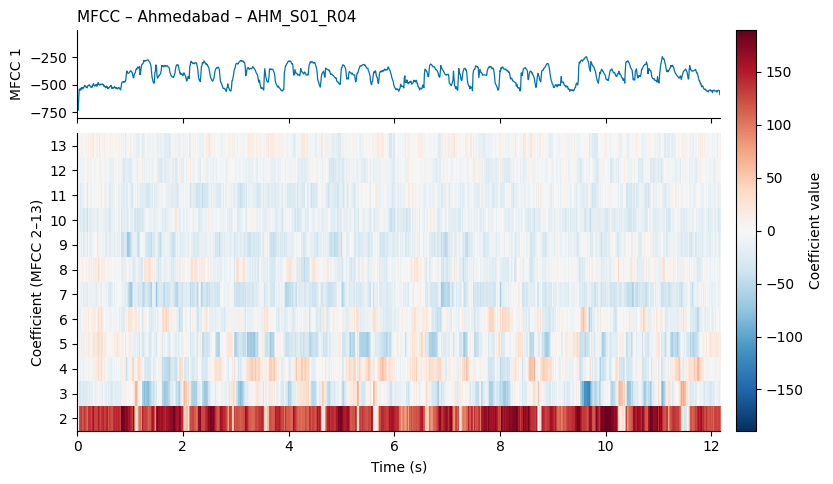

saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R05.png


saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R06.png


saved: results/mfcc/figures/per_recording/mfcc_AHM_S01_R07.png


saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R01.png


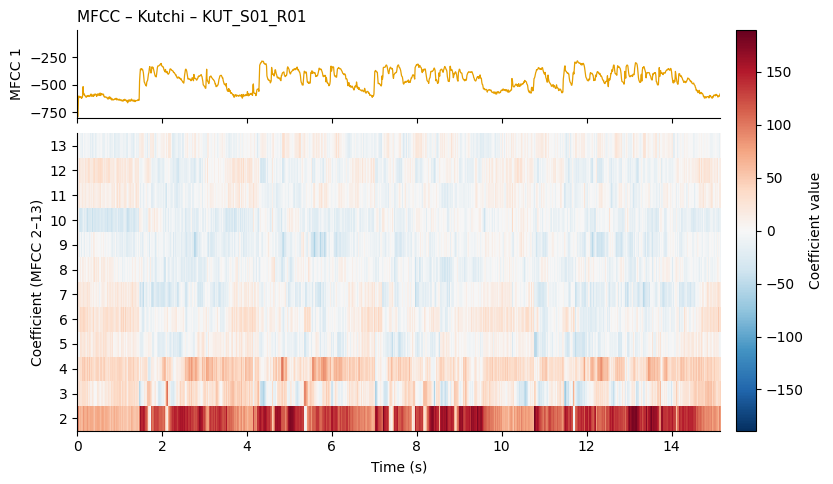

saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R02.png


saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R03.png


saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R04.png


saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R05.png


saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R06.png


saved: results/mfcc/figures/per_recording/mfcc_KUT_S01_R07.png


saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R01.png


saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R02.png


saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R03.png


saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R04.png


saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R05.png


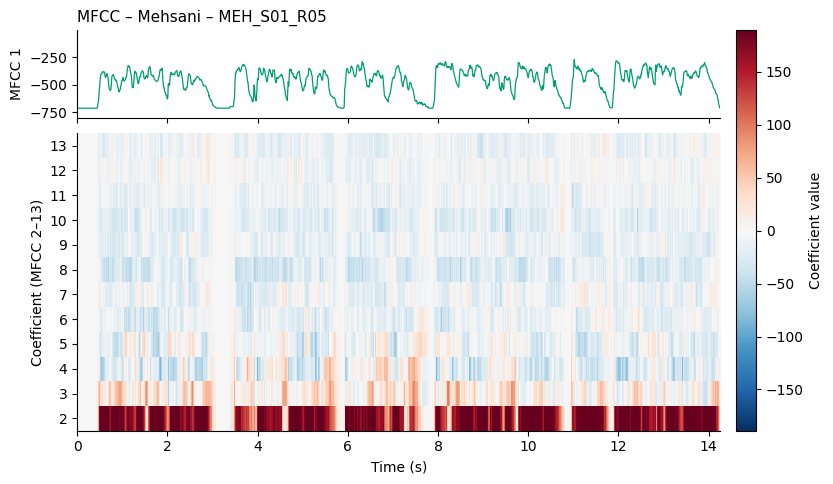

saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R06.png


saved: results/mfcc/figures/per_recording/mfcc_MEH_S01_R07.png


saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R03.png


saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R01.png


saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R02.png


saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R04.png


saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R05.png


saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R06.png


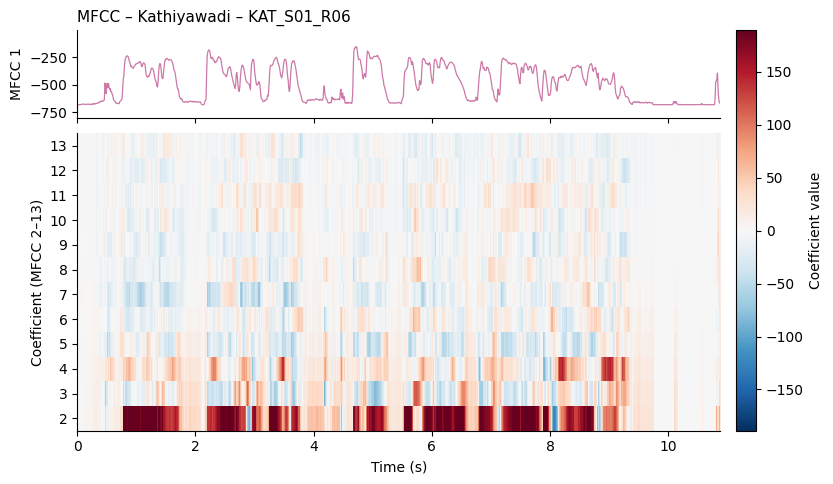

saved: results/mfcc/figures/per_recording/mfcc_KAT_S01_R07.png


In [9]:
reps = aa.representative_recordings(meta)
rep_ids = set(reps["recording_id"])
for _, r in feature_df.iterrows():
    save(draw_mfcc_recording(r["recording_id"], r["accent"]),
         f"per_recording/mfcc_{r['recording_id']}.png", show=r["recording_id"] in rep_ids)

## 9. Figure group 2 – Average MFCC per accent
A time-by-time average across recordings would mix different words and timings, so it would be meaningless. Instead, for each accent we show the **mean value of every coefficient (over frames) for each of its recordings**, side by side, plus the **accent average** on the right. Similar columns = the recordings of that speaker behave alike; the left MFCC 1 panel has its own colour scale.

saved: results/mfcc/figures/accent_average_mfcc_Ahmedabad.png


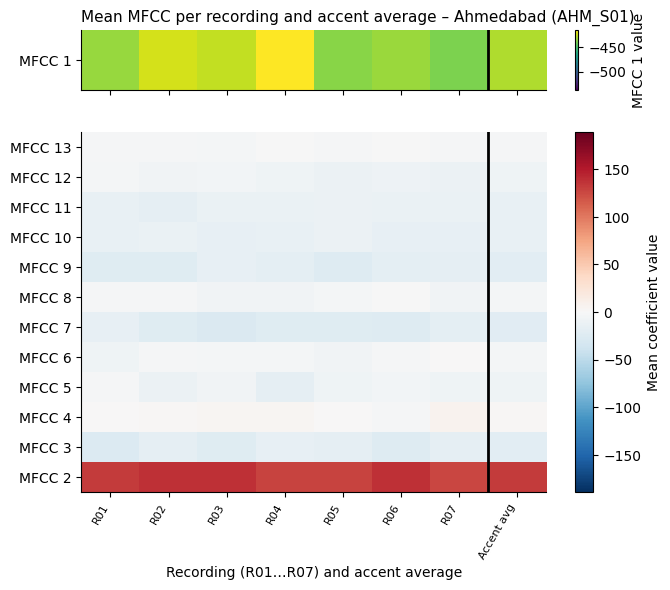

saved: results/mfcc/figures/accent_average_mfcc_Kutchi.png


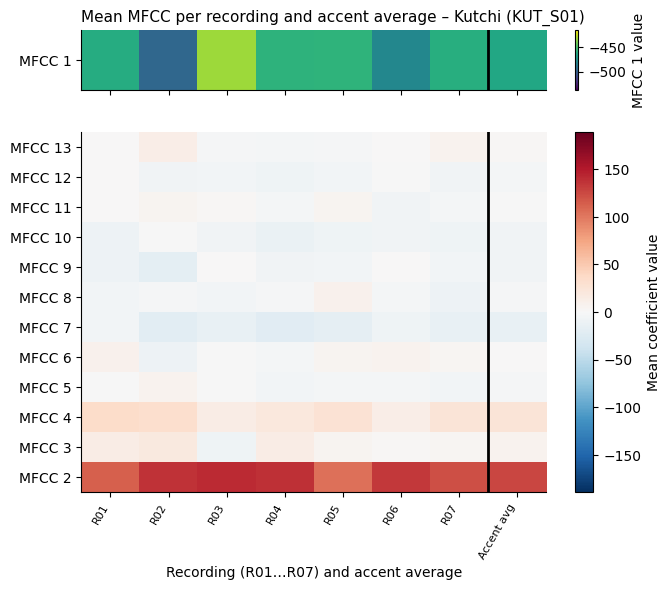

saved: results/mfcc/figures/accent_average_mfcc_Mehsani.png


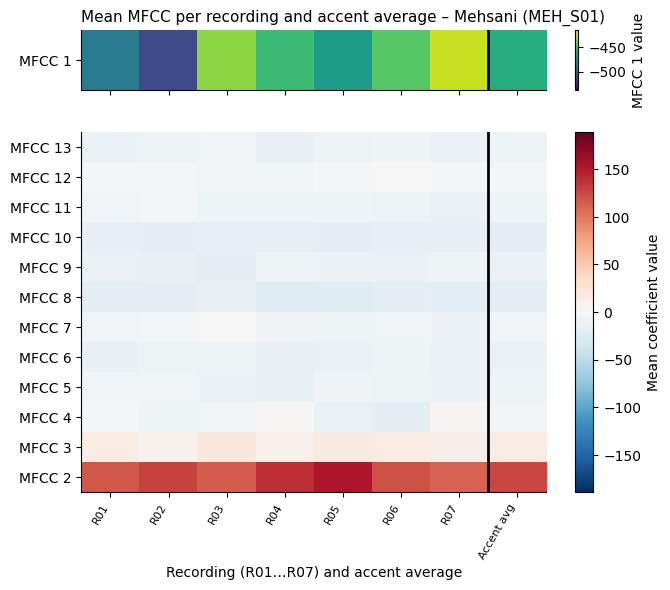

saved: results/mfcc/figures/accent_average_mfcc_Kathiyawadi.png


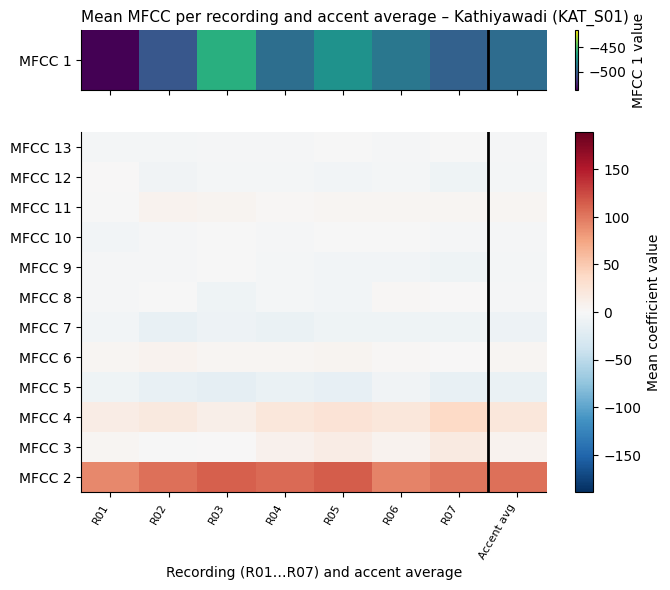

In [10]:
# MFCC 1 colour scale shared by every accent figure (range of all recording-level means)
C1_LIM = (float(feature_df["mfcc_01_mean"].min()), float(feature_df["mfcc_01_mean"].max()))

def coefficient_matrix(sub, group="mfcc"):
    # (13, n_recordings) matrix of recording-level means
    return np.column_stack([sub[f"{group}_{k + 1:02d}_mean"].to_numpy() for k in range(mf.N_COEF)]).T

def draw_two_panel_matrix(ax_a, ax_b, mat, col_labels, accent_cols=None, vmax=VMAX_MFCC):
    # left: MFCC 1 (own scale), right: MFCC 2-13 (shared scale)
    im_a = ax_a.imshow(mat[:1], aspect="auto", cmap="viridis", origin="lower", vmin=C1_LIM[0], vmax=C1_LIM[1])
    ax_a.set_yticks([0]); ax_a.set_yticklabels(["MFCC 1"])
    im_b = ax_b.imshow(mat[1:], aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="lower")
    ax_b.set_yticks(range(12)); ax_b.set_yticklabels([f"MFCC {k}" for k in range(2, 14)])
    for ax in (ax_a, ax_b):
        ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels, rotation=60, ha="right", fontsize=8)
    return im_a, im_b

for accent in [a for a in ACCENTS if a in set(feature_df.accent)]:
    sub = feature_df[feature_df.accent == accent].sort_values("recording_id")
    mat = coefficient_matrix(sub)
    mat = np.column_stack([mat, mat.mean(axis=1)])
    labels = [r.split("_")[-1] for r in sub["recording_id"]] + ["Accent avg"]
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(7.5, 6), gridspec_kw={"height_ratios": [1, 6]})
    im_a, im_b = draw_two_panel_matrix(a0, a1, mat, labels)
    a0.set_xticklabels([]); a0.set_title(f"Mean MFCC per recording and accent average – {accent} ({sub.speaker_id.iloc[0]})", loc="left")
    fig.colorbar(im_a, ax=a0, label="MFCC 1 value"); fig.colorbar(im_b, ax=a1, label="Mean coefficient value")
    for ax in (a0, a1):
        ax.axvline(mat.shape[1] - 1.5, color="black", lw=2)
    a1.set_xlabel("Recording (R01…R07) and accent average")
    save(fig, f"accent_average_mfcc_{accent}.png")

## 10. Figure group 3 – Comparative MFCC heatmaps across accents
**(a) Frame-level:** one representative recording per accent, stacked, same time axis and colour scale. **(b) Accent averages:** the 13 mean coefficient values of each accent side by side. Both use the shared colour scales above. Because each speaker said somewhat different sentences, timing patterns are **not** expected to line up.

saved: results/mfcc/figures/comparison_mfcc_heatmaps_representative.png


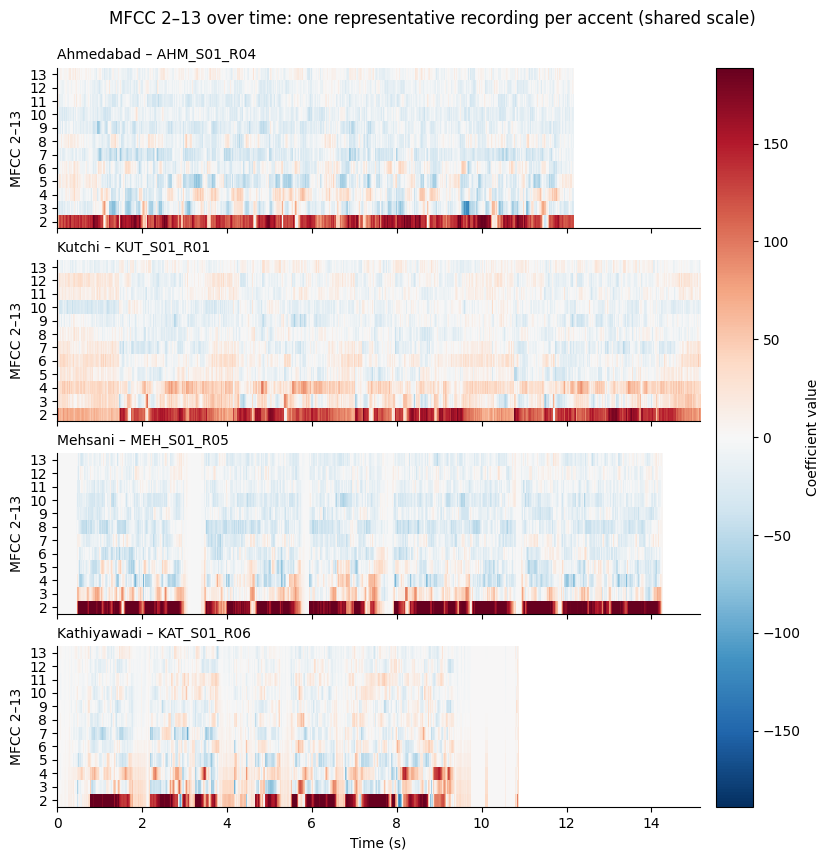

saved: results/mfcc/figures/comparison_mfcc_accent_averages.png


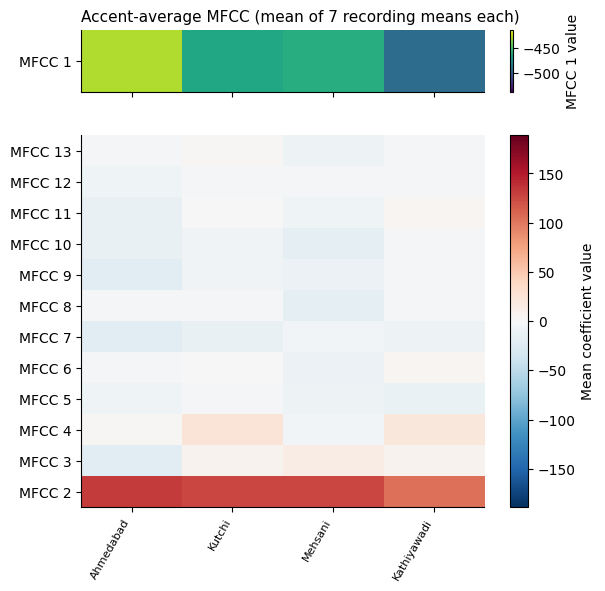

In [11]:
present = [a for a in ACCENTS if a in set(feature_df.accent)]
rep_by_accent = {r["accent"]: r["recording_id"] for _, r in reps.iterrows()}
t_max = max(frames[rep_by_accent[a]]["mfcc"].shape[1] for a in present) * hop_s

fig, axes = plt.subplots(len(present), 1, figsize=(10, 2.4 * len(present)), sharex=True)
for ax, a in zip(np.atleast_1d(axes), present):
    m = frames[rep_by_accent[a]]["mfcc"]
    im = draw_heatmap(ax, m[1:], VMAX_MFCC, first_row=2)
    ax.set_ylabel("MFCC 2–13"); ax.set_title(f"{a} – {rep_by_accent[a]}", loc="left", fontsize=10)
axes[-1].set_xlim(0, t_max); axes[-1].set_xlabel("Time (s)")
fig.colorbar(im, ax=axes, label="Coefficient value", pad=0.02)
fig.suptitle("MFCC 2–13 over time: one representative recording per accent (shared scale)", y=0.94)
save(fig, "comparison_mfcc_heatmaps_representative.png")

mean_by_accent = np.column_stack([coefficient_matrix(feature_df[feature_df.accent == a]).mean(axis=1) for a in present])
fig, (a0, a1) = plt.subplots(2, 1, figsize=(6.5, 6.2), gridspec_kw={"height_ratios": [1, 6]})
im_a, im_b = draw_two_panel_matrix(a0, a1, mean_by_accent, present)
a0.set_xticklabels([]); a0.set_title("Accent-average MFCC (mean of 7 recording means each)", loc="left")
fig.colorbar(im_a, ax=a0, label="MFCC 1 value"); fig.colorbar(im_b, ax=a1, label="Mean coefficient value")
save(fig, "comparison_mfcc_accent_averages.png")

## 11. Figure group 4 – Distribution of each coefficient by accent
Each panel is one coefficient. Each box summarises **all frames** of that accent (middle half of the frames = the box, line = median); black dots are the 7 **recording-level means**, which show how much recordings of the same speaker differ from each other. Frames from pauses/silence are included. MFCC 1 and its extreme low values mostly reflect silence and loudness.

saved: results/mfcc/figures/distributions_mfcc_by_accent.png


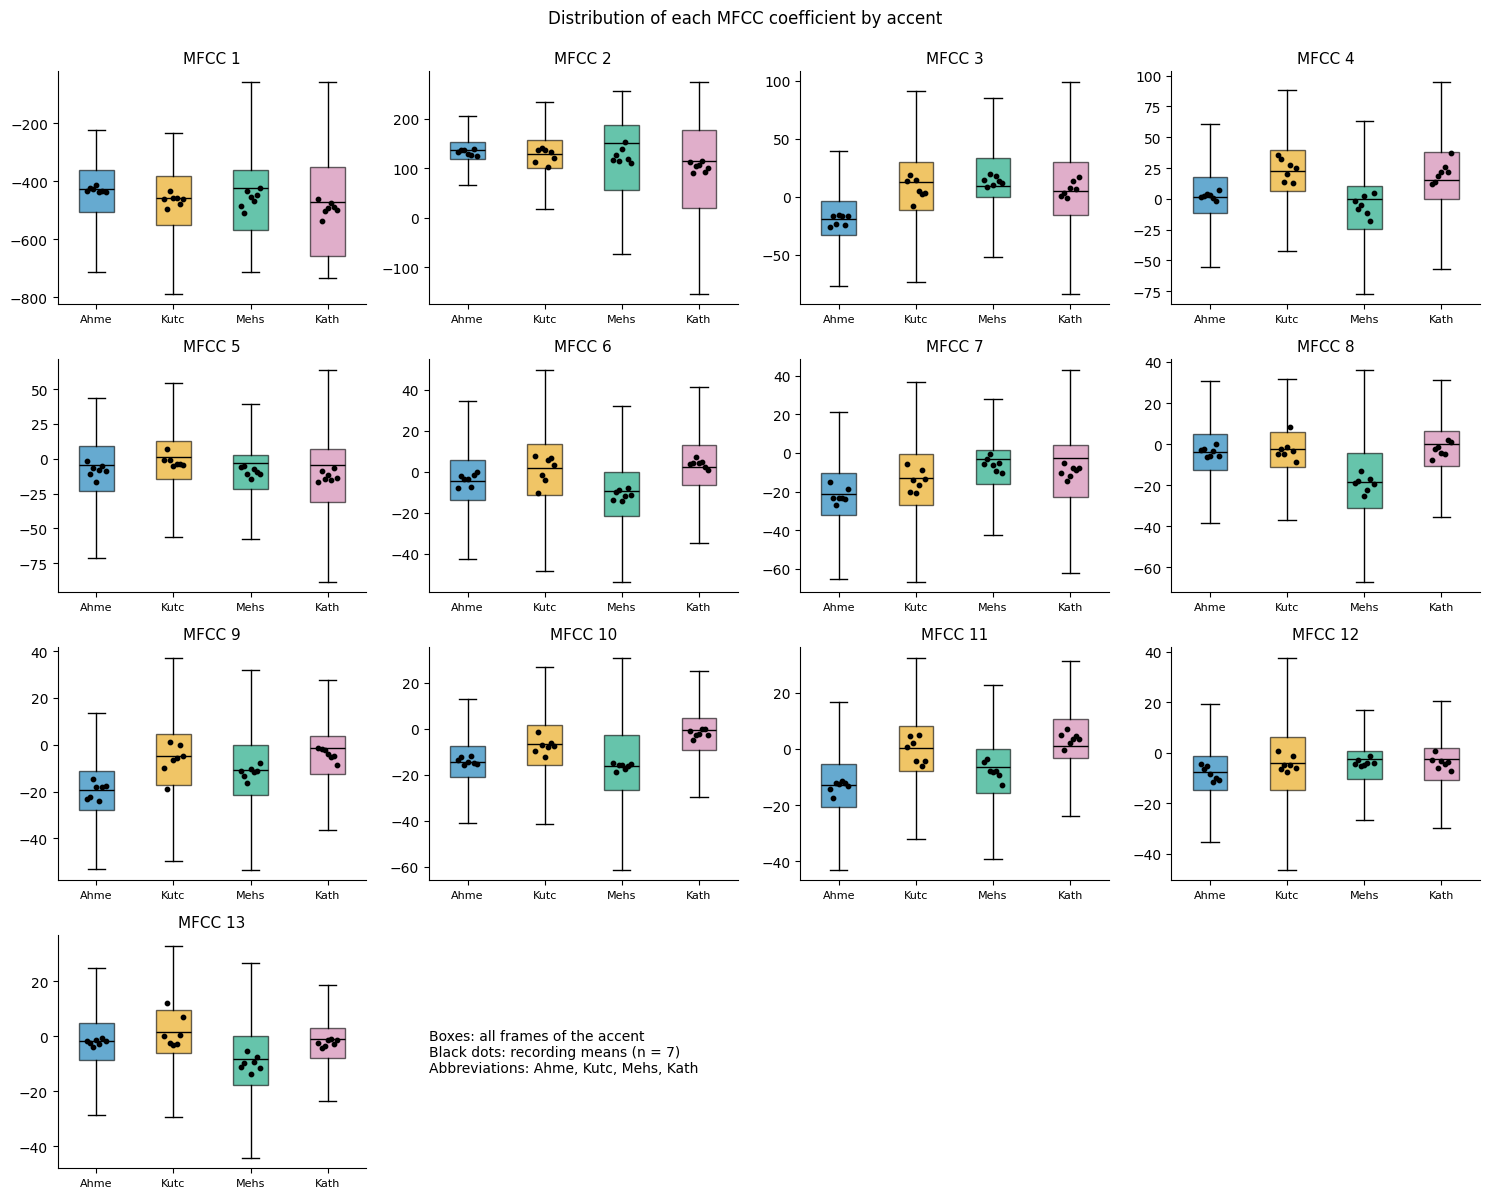

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.ravel()
for k in range(mf.N_COEF):
    ax = axes[k]
    data = [np.concatenate([frames[r]["mfcc"][k] for r in feature_df.loc[feature_df.accent == a, "recording_id"]]) for a in present]
    bp = ax.boxplot(data, tick_labels=[a[:4] for a in present], patch_artist=True, showfliers=False,
                    medianprops={"color": "black"})
    for patch, a in zip(bp["boxes"], present):
        patch.set_facecolor(COLORS[a]); patch.set_alpha(0.6)
    for i, a in enumerate(present):
        v = feature_df.loc[feature_df.accent == a, f"mfcc_{k + 1:02d}_mean"]
        ax.scatter(np.full(len(v), i + 1) + np.linspace(-0.12, 0.12, len(v)), v, color="black", s=10, zorder=3)
    ax.set_title(mf.coef_label(k)); ax.tick_params(axis="x", labelsize=8)
for ax in axes[mf.N_COEF:]:
    ax.axis("off")
axes[13].text(0, 0.6, "Boxes: all frames of the accent" + chr(10) + "Black dots: recording means (n = 7)" + chr(10)
              + "Abbreviations: Ahme, Kutc, Mehs, Kath", fontsize=10, va="top")
fig.suptitle("Distribution of each MFCC coefficient by accent", y=0.995)
fig.tight_layout(); save(fig, "distributions_mfcc_by_accent.png")

## 12. Figure group 5 – Delta MFCC and delta-delta MFCC
**Delta** = how fast each coefficient is changing from frame to frame (speed). **Delta-delta** = how fast that change is itself changing (acceleration). Heatmaps below use a symmetric scale shared by all four accents. The second figure compares, per coefficient, how much the delta / delta-delta values fluctuate within a recording (mean within-recording standard deviation, averaged over each accent's recordings).

saved: results/mfcc/figures/comparison_delta_heatmaps_representative.png


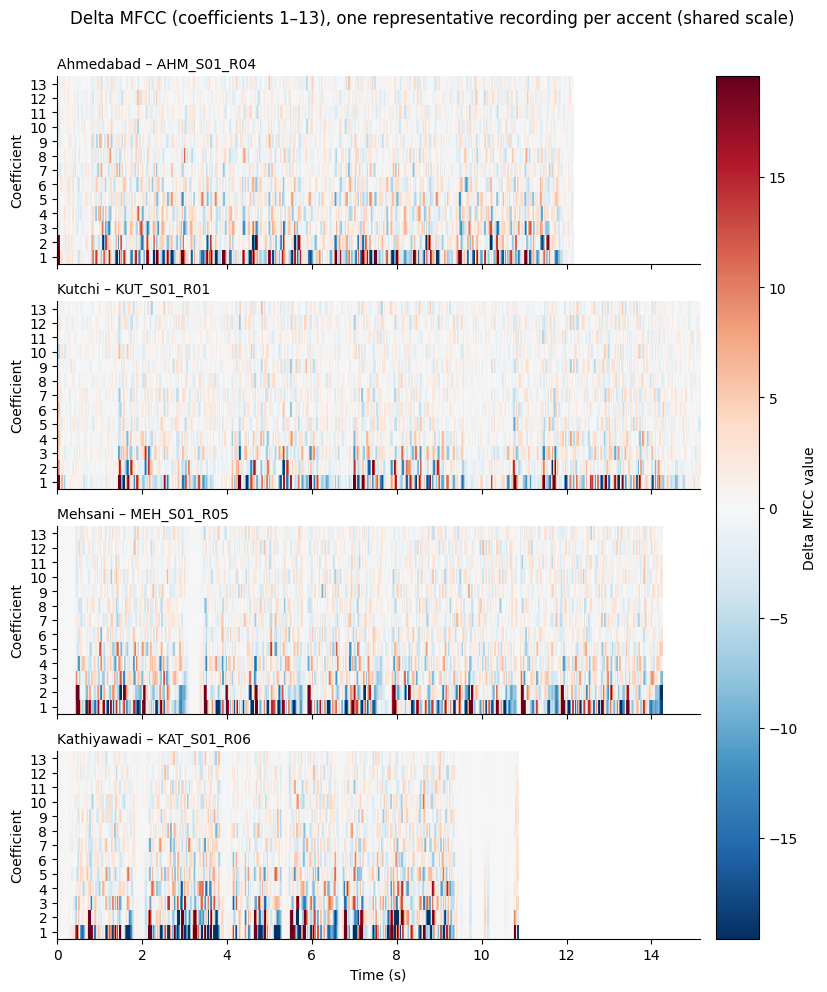

saved: results/mfcc/figures/comparison_delta2_heatmaps_representative.png


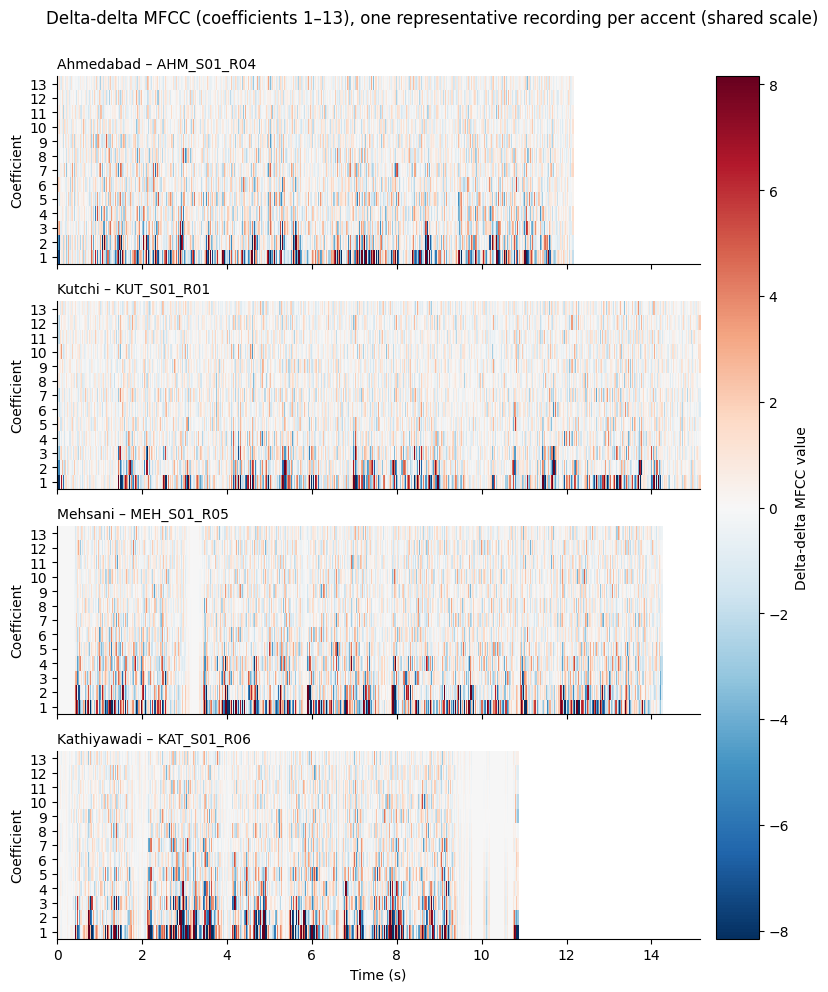

saved: results/mfcc/figures/delta_variability_by_accent.png


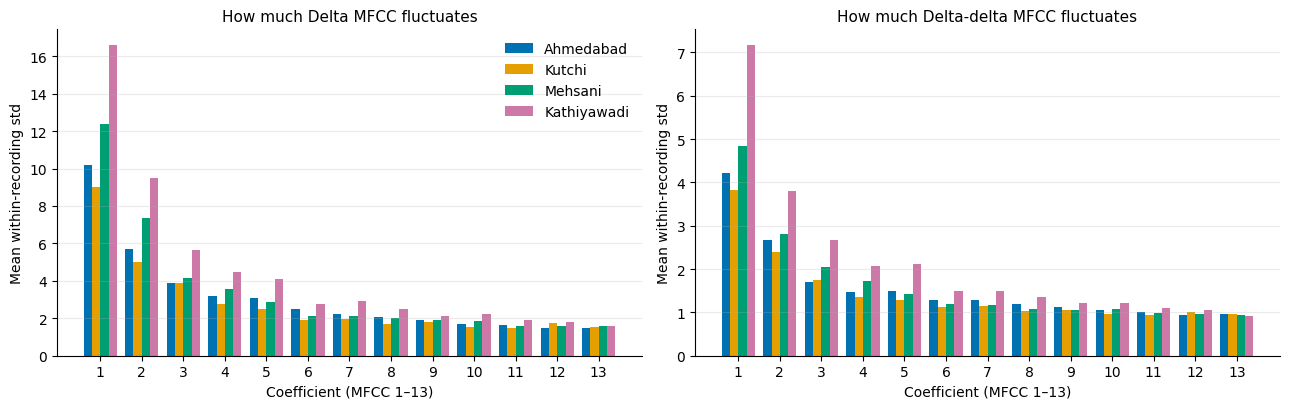

In [13]:
for key, vmax, title, fname in [("delta", VMAX_DELTA, "Delta MFCC", "comparison_delta_heatmaps_representative.png"),
                                ("delta2", VMAX_DELTA2, "Delta-delta MFCC", "comparison_delta2_heatmaps_representative.png")]:
    fig, axes = plt.subplots(len(present), 1, figsize=(10, 2.8 * len(present)), sharex=True)
    for ax, a in zip(np.atleast_1d(axes), present):
        m = frames[rep_by_accent[a]][key]
        im = draw_heatmap(ax, m, vmax, first_row=1)
        ax.set_ylabel("Coefficient"); ax.set_title(f"{a} – {rep_by_accent[a]}", loc="left", fontsize=10)
    axes[-1].set_xlim(0, t_max); axes[-1].set_xlabel("Time (s)")
    fig.colorbar(im, ax=axes, label=f"{title} value", pad=0.02)
    fig.suptitle(f"{title} (coefficients 1–13), one representative recording per accent (shared scale)", y=0.94)
    save(fig, fname)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
x = np.arange(1, mf.N_COEF + 1); width = 0.8 / len(present)
for ax, key, title in zip(axes, ["delta", "delta2"], ["Delta MFCC", "Delta-delta MFCC"]):
    for j, a in enumerate(present):
        sub = feature_df[feature_df.accent == a]
        vals = [sub[f"{key}_{k + 1:02d}_std"].mean() for k in range(mf.N_COEF)]
        ax.bar(x + (j - (len(present) - 1) / 2) * width, vals, width, color=COLORS[a], label=a)
    ax.set_xlabel("Coefficient (MFCC 1–13)"); ax.set_ylabel("Mean within-recording std")
    ax.set_title(f"How much {title} fluctuates"); ax.set_xticks(x); ax.grid(axis="y", alpha=0.25)
axes[0].legend(frameon=False)
fig.tight_layout(); save(fig, "delta_variability_by_accent.png")

## 13. Figure group 6 – Recording-level MFCC means across accents
Each thin line is one recording (its 13 mean coefficients); thick lines are accent averages. Left: MFCC 1 (own axis). Right: MFCC 2–13. Lines of the same colour staying close together means the recordings of that speaker are similar to each other; this says nothing yet about differences between accents in general.

saved: results/mfcc/figures/recording_means_by_accent.png


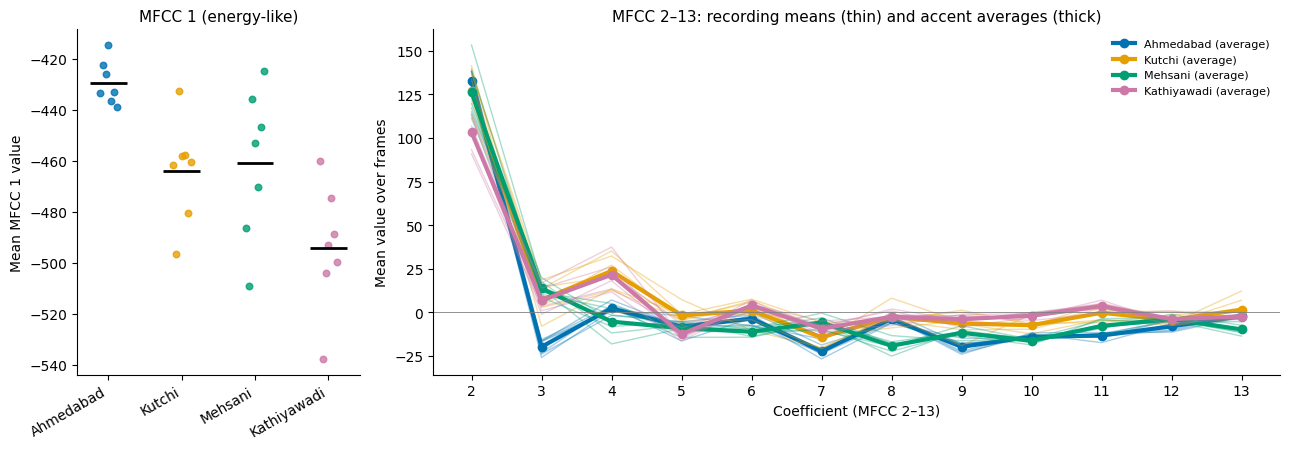

In [14]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 3]})
for a in present:
    sub = feature_df[feature_df.accent == a]
    mat = coefficient_matrix(sub)                        # (13, n)
    pos = np.full(mat.shape[1], present.index(a)) + np.linspace(-0.12, 0.12, mat.shape[1])
    a0.scatter(pos, mat[0], color=COLORS[a], s=22, alpha=0.8)
    a0.hlines(mat[0].mean(), present.index(a) - 0.25, present.index(a) + 0.25, color="black", lw=2)
    for j in range(mat.shape[1]):
        a1.plot(range(2, 14), mat[1:, j], color=COLORS[a], alpha=0.35, lw=1)
    a1.plot(range(2, 14), mat[1:].mean(axis=1), color=COLORS[a], lw=3, marker="o", label=f"{a} (average)")
a0.set_xticks(range(len(present))); a0.set_xticklabels(present, rotation=30, ha="right")
a0.set_ylabel("Mean MFCC 1 value"); a0.set_title("MFCC 1 (energy-like)")
a1.set_xticks(range(2, 14)); a1.set_xlabel("Coefficient (MFCC 2–13)"); a1.set_ylabel("Mean value over frames")
a1.set_title("MFCC 2–13: recording means (thin) and accent averages (thick)"); a1.legend(frameon=False, fontsize=8)
a1.axhline(0, color="grey", lw=0.6)
fig.tight_layout(); save(fig, "recording_means_by_accent.png")

## 14. Figure group 7 – Additional views for interpretation
**(a) All 28 recordings at a glance:** one row per recording (grouped by accent), one column per coefficient (MFCC 2–13). Left-side labels show accent and original format. **(b) MFCC 1 versus Phase 2 loudness and noise measurements:** is MFCC 1 mostly telling us about recording level/background rather than speech content?

saved: results/mfcc/figures/all_recordings_mean_mfcc_heatmap.png


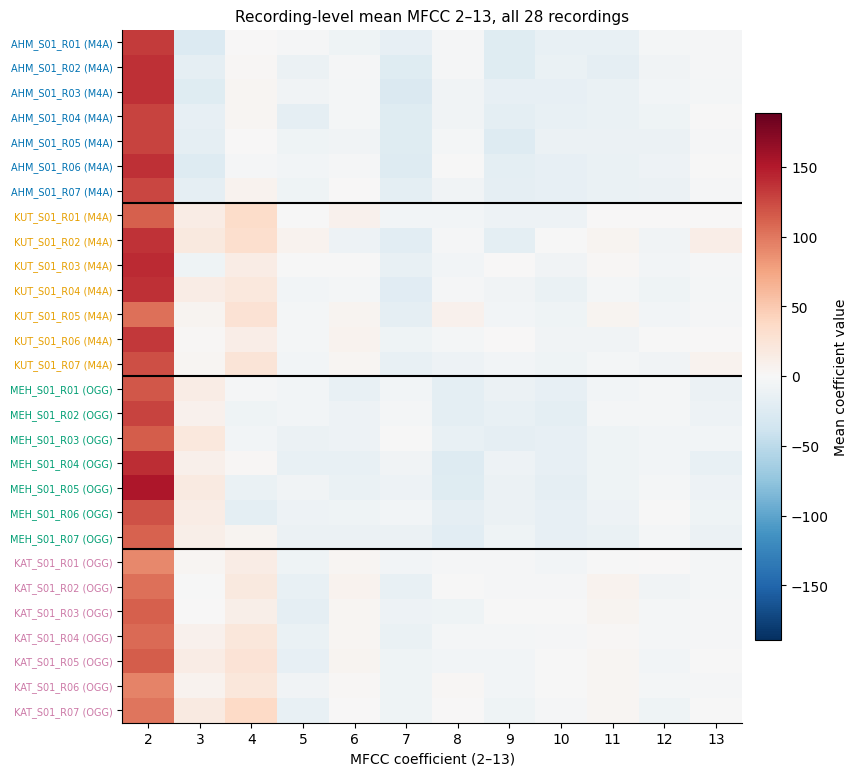

saved: results/mfcc/figures/mfcc1_vs_level_and_noise.png


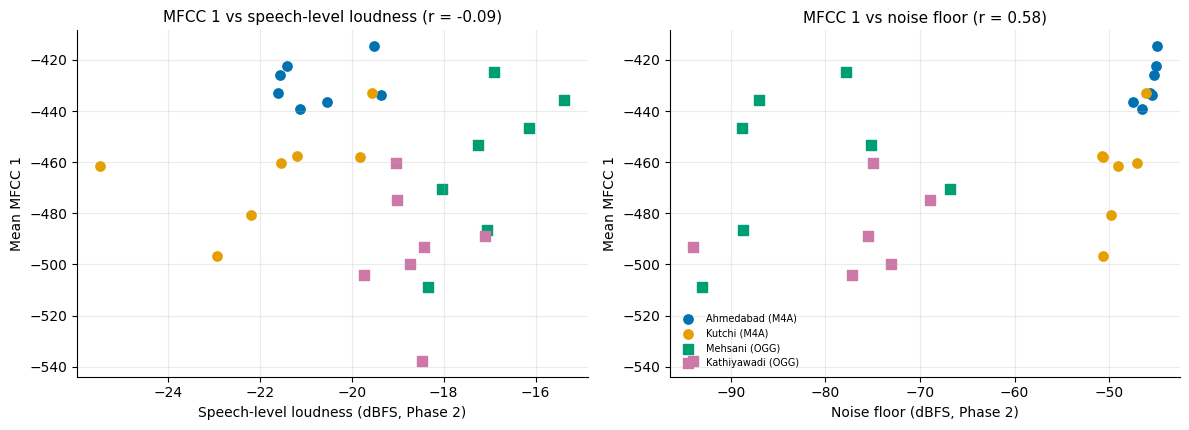

Correlations of mean MFCC 1 (n = 28; descriptive only):
mfcc_01_mean        1.00
speech_rms_dbfs    -0.09
noise_floor_dbfs    0.58
Name: mfcc_01_mean, dtype: float64


In [15]:
order = feature_df.sort_values(["accent", "recording_id"], key=lambda s: s.map({a: i for i, a in enumerate(ACCENTS)}) if s.name == "accent" else s)
mat = np.column_stack([order[f"mfcc_{k + 1:02d}_mean"].to_numpy() for k in range(1, mf.N_COEF)])
fig, ax = plt.subplots(figsize=(8.5, 9))
im = ax.imshow(mat, aspect="auto", cmap="RdBu_r", vmin=-VMAX_MFCC, vmax=VMAX_MFCC)
ax.set_xticks(range(12)); ax.set_xticklabels([f"{k}" for k in range(2, 14)]); ax.set_xlabel("MFCC coefficient (2–13)")
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{r.recording_id} ({r.original_format})" for r in order.itertuples()], fontsize=7)
bounds = np.flatnonzero(order["accent"].to_numpy()[1:] != order["accent"].to_numpy()[:-1]) + 0.5
for b in bounds:
    ax.axhline(b, color="black", lw=1.5)
for i, accent in enumerate(order["accent"]):
    ax.get_yticklabels()[i].set_color(COLORS[accent])
fig.colorbar(im, ax=ax, label="Mean coefficient value", fraction=0.04, pad=0.02)
ax.set_title("Recording-level mean MFCC 2–13, all 28 recordings")
save(fig, "all_recordings_mean_mfcc_heatmap.png")

merged = feature_df.merge(meta[["recording_id", "speech_rms_dbfs", "noise_floor_dbfs"]], on="recording_id")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, col, label in zip(axes, ["speech_rms_dbfs", "noise_floor_dbfs"],
                          ["Speech-level loudness (dBFS, Phase 2)", "Noise floor (dBFS, Phase 2)"]):
    for a in present:
        for fmt in ["M4A", "OGG"]:
            s = merged[(merged.accent == a) & (merged.original_format == fmt)]
            ax.scatter(s[col], s["mfcc_01_mean"], color=COLORS[a], marker=MARKERS[fmt], s=45,
                       label=f"{a} ({fmt})" if len(s) else None)
    r = np.corrcoef(merged[col], merged["mfcc_01_mean"])[0, 1]
    ax.set_xlabel(label); ax.set_ylabel("Mean MFCC 1"); ax.set_title(f"MFCC 1 vs {label.split(' (')[0].lower()} (r = {r:.2f})")
    ax.grid(alpha=0.25)
axes[1].legend(frameon=False, fontsize=7, loc="lower left")
fig.tight_layout(); save(fig, "mfcc1_vs_level_and_noise.png")
print("Correlations of mean MFCC 1 (n = 28; descriptive only):")
print(merged[["mfcc_01_mean", "speech_rms_dbfs", "noise_floor_dbfs"]].corr().round(2)["mfcc_01_mean"])

## 15. Save the extraction and validation summary

In [16]:
summary_text = mf.format_validation_summary(meta, feature_df, frames, errors, checks, all_passed)
(mf.MFCC_DIR / "extraction_validation_summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)
print("Files in results/mfcc/:")
for p in sorted(mf.MFCC_DIR.rglob("*")):
    if p.is_file() and p.name != "README.md":
        print("  ", p.relative_to(mf.MFCC_DIR).as_posix())

Phase 3 – MFCC extraction and validation summary

Extraction parameters:
  sample_rate : 16000
  n_mfcc      : 13
  n_fft       : 512
  hop_length  : 160
  win_length  : 400
  window      : hann
  dct_type    : 2
  norm        : ortho
  n_mels      : 128
  center      : True
  delta_width : 9

Recordings in metadata : 28
Recordings processed   : 28
Extraction errors      : 0

Recordings per accent:
  Ahmedabad   : 7
  Kutchi      : 7
  Mehsani     : 7
  Kathiyawadi : 7
  Surti       : 0  (pending future collection)

Frames per recording   : min 960, max 1826, total 38127
Features per recording : 13 coefficients x (MFCC, delta, delta-delta) x (mean, std) = 78
Recordings with Phase 2 quality flags kept: 11

Validation checks:
  [PASS] No extraction errors
  [PASS] All metadata recordings processed  -> metadata=28, processed=28
  [PASS] Feature table has one row per recording, IDs match metadata
  [PASS] Every recording has 13 coefficients; MFCC/delta/delta-delta shapes agree with frame c

## 16. Observations, limitations and what comes next

**Observations (descriptive, from the tables and figures above)**
- All 28 recordings produced valid 13 x T MFCC, delta and delta-delta matrices with no NaN/infinite values, and all validation checks passed. Flagged recordings were kept.
- Some mean coefficients differ between accents by more than the recording-to-recording spread within an accent, for example MFCC 3 (Ahmedabad about -20 versus about +7 to +14 for the others) and MFCC 8 (Mehsani about -19 versus about -2.5 to -4 for the others). See `mfcc_accent_summary.csv`.
- Mean MFCC 1 is lower for Kathiyawadi (about -494) than the other accents (about -429 to -464). It is moderately related to the Phase 2 noise floor (r = 0.58, n = 28) and only weakly to speech loudness (r = -0.09), so it largely reflects how much of a recording is silence or background noise.
- Delta and delta-delta values fluctuate most for Kathiyawadi and least for Kutchi.

**Possible explanations (not tested)**: speaker voice, microphone/app, original format (M4A vs OGG), background noise or noise gating, sentence wording, and the amount of silence kept in each recording.

**Limitations**: one speaker per accent, 7 recordings each, silence frames included, MFCCs not normalised, no statistical testing. Nothing here shows that MFCCs discriminate regional accents, or that any coefficient is an accent trait.

**Next (Phase 4)**: compare features across accents with these caveats in mind. Phase 3 stops here; no PCA, feature selection or classification was performed.